# Course 16: Algorithms Behind Modern AI
## Session 6: Dynamic programming II: Viterbi, the forward algorithm and CTC

**Goal:** find the best path and the total probability over exponentially many paths with one table, implement Viterbi and the forward algorithm in log space, and compute the CTC loss from scratch, checked against brute force and against PyTorch.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. By hand first: the best way to cut `nowhere` into pieces
A **unigram tokenizer** has a vocabulary of pieces, each with a probability. The probability of one **segmentation** (one way to cut a string into pieces) is the product of its pieces' probabilities, and the tokenizer wants the segmentation with the largest product (Kudo 2018).

Our string has seven letters, `nowhere`, and the vocabulary has six pieces:

| piece | `no` | `here` | `where` | `now` | `n` | `o` |
|---|---|---|---|---|---|---|
| probability | 1/2 | 1/4 | 1/8 | 1/16 | 1/32 | 1/32 |
| cost = −log₂(probability), in bits | 1 | 2 | 3 | 4 | 5 | 5 |

A product of probabilities is largest when the **sum of the costs** is smallest, so we can work with small whole numbers.

Draw a **lattice**: eight nodes in a row, one for each position 0, 1, …, 7 between the letters. Every piece that matches the text is an edge from its start position to its end position (`no` goes from 0 to 2, `where` from 2 to 7, and so on). A segmentation is a path from node 0 to node 7. All edges point to the right, so the lattice is a directed acyclic graph and "left to right" is a topological order (session 4).

The four parts of the dynamic program (session 5's recipe):

1. **Subproblems:** `best[i]` = the smallest cost of any segmentation of the first $i$ letters.
2. **Recurrence:** look at the last piece. If it starts at $j$, the rest is a best segmentation of the first $j$ letters: `best[i]` = min over pieces `text[j:i]` in the vocabulary of `best[j] + cost(text[j:i])`. Also store `back[i]`, the $j$ that won (a **back-pointer**).
3. **Order:** $i = 1, 2, \dots, 7$. `best[0] = 0`; a position that no path reaches keeps the cost ∞.
4. **Answer:** `best[7]`; follow the back-pointers from 7 to 0 to read the pieces.

On paper: fill `best` and `back` for the eight positions. Which segmentation wins? Which one do you get if you always take the **longest** piece that matches, from left to right? Then run the cell. (The code keeps log-probabilities and maximizes their sum, which is the same thing; it prints them as bits.)

In [1]:
import os
for _v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[_v] = "1"              # one thread for NumPy; set before NumPy is imported
import itertools, math, time
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
import torch                          # used only in section 7, to check our CTC loss
import torch.nn.functional as F
torch.set_num_threads(1)

t_start = time.time()
NEG = float("-inf")                   # log 0: "no path reaches this place"

def viterbi_segment(text, logp, max_len):
    # best[i] = the largest total log-probability of any segmentation of text[:i]
    # back[i] = the position where the last piece of that segmentation starts
    n = len(text)
    best, back, lookups = [NEG] * (n + 1), [None] * (n + 1), 0
    best[0] = 0.0                                        # the empty beginning: log 1
    for i in range(1, n + 1):                            # every end position, left to right
        for j in range(max(0, i - max_len), i):          # every possible start of the last piece text[j:i]
            lookups += 1
            piece = text[j:i]
            if piece in logp and best[j] + logp[piece] > best[i]:
                best[i], back[i] = best[j] + logp[piece], j
    if best[n] == NEG:
        return None, best, back, lookups                 # the text cannot be cut into vocabulary pieces
    pieces, i = [], n
    while i > 0:                                         # follow the back-pointers from the end
        pieces.append(text[back[i]:i]); i = back[i]
    return pieces[::-1], best, back, lookups

VOCAB1 = {"no": Fraction(1, 2), "here": Fraction(1, 4), "where": Fraction(1, 8),
          "now": Fraction(1, 16), "n": Fraction(1, 32), "o": Fraction(1, 32)}
logp1 = {piece: math.log(p) for piece, p in VOCAB1.items()}
print("the six probabilities add up to", sum(VOCAB1.values()))

def bits(b):
    return "inf" if b == NEG else f"{(0.0 - b) / math.log(2):.0f}"

text = "nowhere"
pieces1, best1, back1, lookups1 = viterbi_segment(text, logp1, max_len=5)
n = len(text)
print("end position i     " + "".join(f"{i:>8d}" for i in range(n + 1)))
print("letters before i   " + "".join(f"{text[:i] or '(none)':>8s}" for i in range(n + 1)))
print("best cost in bits  " + "".join(f"{bits(b):>8s}" for b in best1))
print("back-pointer       " + "".join(f"{'-' if j is None else j:>8}" for j in back1))
print("last piece         " + "".join(f"{'-' if j is None else text[j:i]:>8s}" for i, j in enumerate(back1)))
p_best1 = math.prod(VOCAB1[p] for p in pieces1)
print("best segmentation:", " | ".join(pieces1), "with probability", p_best1, f"= 2^-{bits(best1[n])}")
print("vocabulary lookups:", lookups1, "= 1 + 2 + 3 + 4 + 5 + 5 + 5 (pieces of up to 5 letters ending at each position)")

the six probabilities add up to 1
end position i            0       1       2       3       4       5       6       7
letters before i     (none)       n      no     now    nowh   nowhe  nowher nowhere
best cost in bits         0       5       1       4     inf     inf     inf       4
back-pointer              -       0       0       0       -       -       -       2
last piece                -       n      no     now       -       -       -   where
best segmentation: no | where with probability 1/16 = 2^-4
vocabulary lookups: 25 = 1 + 2 + 3 + 4 + 5 + 5 + 5 (pieces of up to 5 letters ending at each position)


### 2. Viterbi against brute force and against greedy longest match
A string of $n$ letters has $n - 1$ places where a cut can be made, so it has $2^{n-1}$ possible segmentations. **Brute force** tries every one and keeps those whose pieces are all in the vocabulary. The table of section 1 looks only at the pieces that end at each position: at most $L$ lookups per position if the longest piece has $L$ letters, so at most $n \cdot L$ lookups. (Each lookup here hashes a substring of up to $L$ letters. Session 3's trie makes each step $O(1)$ by walking the text and the trie together.)

This way of finding the best path in a lattice is the **Viterbi algorithm** (Viterbi 1967): keep the best score into every node, and a back-pointer.

**Greedy longest match** (session 3) is a different algorithm: at each position it takes the longest piece that matches and never looks back. It is fast, but nothing says it finds the most probable segmentation.

The cell checks all three on `nowhere`, then on 300 random strings over the letters `a`, `b`, `c`, each with its own random vocabulary (synthetic). Then three Bangla words with a small vocabulary whose counts are made up for this example. A piece is a sequence of Unicode code points here, and a vowel sign such as `ে` is a code point of its own (Course 5 session 2). A real unigram tokenizer learns its probabilities from a corpus with the EM algorithm and prunes the vocabulary (Kudo 2018); we only write probabilities down.

In [2]:
def brute_force_segment(text, logp):
    # try each of the 2^(n-1) ways to cut the text; keep those whose pieces are all in the vocabulary
    n = len(text)
    valid, best, best_pieces = [], NEG, None
    for mask in range(2 ** (n - 1)):                     # bit k of mask is 1: cut after letter k
        pieces, start = [], 0
        for k in range(n - 1):
            if mask >> k & 1:
                pieces.append(text[start:k + 1]); start = k + 1
        pieces.append(text[start:])
        if all(p in logp for p in pieces):
            score = sum(logp[p] for p in pieces)
            valid.append((score, pieces))
            if score > best:
                best, best_pieces = score, pieces
    return best_pieces, best, valid, 2 ** (n - 1)

def greedy_longest(text, logp, max_len):
    # at each position take the longest vocabulary piece that matches; never look back
    pieces, i = [], 0
    while i < len(text):
        for l in range(min(max_len, len(text) - i), 0, -1):
            if text[i:i + l] in logp:
                pieces.append(text[i:i + l]); i += l
                break
        else:
            return None                                  # stuck: no piece starts here
    return pieces

_, _, valid, tried = brute_force_segment("nowhere", logp1)
print(f"nowhere: {tried} ways to cut, {len(valid)} of them use only vocabulary pieces:")
for score, pcs in sorted(valid, key=lambda v: -v[0]):
    print(f"   {' | '.join(pcs):14s} probability {str(math.prod(VOCAB1[p] for p in pcs)):7s} cost {bits(score):>2s} bits")
total1 = sum(math.prod(VOCAB1[p] for p in pcs) for _, pcs in valid)
print("   sum over all segmentations:", total1, f"= {float(total1):.5f}")
g = greedy_longest("nowhere", logp1, 5)
print("greedy longest match:", " | ".join(g), "with probability", math.prod(VOCAB1[p] for p in g),
      "-> the Viterbi segmentation is", p_best1 / math.prod(VOCAB1[p] for p in g), "x more probable")

rng = np.random.default_rng(6)
letters = list("abc")
def random_vocab(n_pieces=12, max_len=4):
    pcs = set(letters)                                   # every single letter, so that no string can fail
    while len(pcs) < n_pieces:
        pcs.add("".join(rng.choice(letters, size=rng.integers(2, max_len + 1))))
    pcs = sorted(pcs)
    return dict(zip(pcs, np.log(rng.dirichlet(np.ones(len(pcs))))))

same_score = same_pieces = greedy_same = greedy_worse = 0
for trial in range(300):
    lp = random_vocab()
    s = "".join(rng.choice(letters, size=rng.integers(1, 13)))
    v_pieces, v_best, _, _ = viterbi_segment(s, lp, 4)
    b_pieces, b_best, _, _ = brute_force_segment(s, lp)
    same_score += abs(v_best[-1] - b_best) < 1e-9
    same_pieces += v_pieces == b_pieces
    g_score = sum(lp[p] for p in greedy_longest(s, lp, 4))
    greedy_same += abs(g_score - b_best) < 1e-9
    greedy_worse += g_score < b_best - 1e-9
print(f"\n300 random strings (1 to 12 letters), each with a random vocabulary of 12 pieces:")
print(f"   Viterbi = brute force: same best score in {same_score}, same pieces in {same_pieces}")
print(f"   greedy longest match: best score in {greedy_same}, a lower score in {greedy_worse}")

lp, L = random_vocab(), 4
print(f"\n{'letters n':>9s} | {'ways to cut 2^(n-1)':>31s} | {'valid (brute force)':>19s} | {'Viterbi lookups':>15s} | {'n * L':>5s}")
for n_ in [4, 8, 12, 16, 20, 40, 80]:
    s = "".join(rng.choice(letters, size=n_))
    t0 = time.perf_counter(); _, v_best, _, lookups = viterbi_segment(s, lp, L); t_v = time.perf_counter() - t0
    assert lookups == sum(min(i, L) for i in range(1, n_ + 1))
    if n_ <= 16:
        t0 = time.perf_counter(); _, b_best, valid, tried = brute_force_segment(s, lp); t_b = time.perf_counter() - t0
        assert abs(b_best - v_best[-1]) < 1e-9 and tried == 2 ** (n_ - 1)
    print(f"{n_:9d} | {2 ** (n_ - 1):31,d} | {len(valid) if n_ <= 16 else '(not run)':>19} | {lookups:15d} | {n_ * L:5d}")
    if n_ == 16:
        t16 = (t_b, t_v)
print(f"time for n = 16: brute force {t16[0] * 1e3:.1f} ms, Viterbi {t16[1] * 1e3:.3f} ms")

# Bangla: pieces with made-up counts (synthetic). Every single code point of the test words gets count 1.
BN_COUNTS = {"বাংলাদেশ": 40, "বাংলাদেশে": 12, "বাংলা": 30, "দেশ": 25, "দেশে": 10, "দেশের": 8, "ের": 60,
             "আমাদের": 9, "আমার": 15, "আমা": 6, "দের": 20}
bn_words = ["বাংলাদেশের", "দেশের", "আমাদের"]
for ch in sorted(set("".join(bn_words))):
    BN_COUNTS.setdefault(ch, 1)
bn_total = sum(BN_COUNTS.values())
bn_logp = {p: math.log(c / bn_total) for p, c in BN_COUNTS.items()}
bn_L = max(len(p) for p in BN_COUNTS)
print(f"\nBangla vocabulary: {len(BN_COUNTS)} pieces, total count {bn_total}, longest piece {bn_L} code points")
for w in bn_words:
    v, vb, _, _ = viterbi_segment(w, bn_logp, bn_L)
    b, bb, valid, tried = brute_force_segment(w, bn_logp)
    g = greedy_longest(w, bn_logp, bn_L)
    assert v == b
    print(f"{w} ({len(w)} code points, {tried} ways to cut, {len(valid)} valid)")
    print(f"   Viterbi: {' | '.join(v):24s} probability {math.exp(vb[-1]):.6f}")
    print(f"   greedy : {' | '.join(g):24s} probability {math.exp(sum(bn_logp[p] for p in g)):.6f}")

nowhere: 64 ways to cut, 3 of them use only vocabulary pieces:
   no | where     probability 1/16    cost  4 bits
   now | here     probability 1/64    cost  6 bits
   n | o | where  probability 1/8192  cost 13 bits
   sum over all segmentations: 641/8192 = 0.07825
greedy longest match: now | here with probability 1/64 -> the Viterbi segmentation is 4 x more probable

300 random strings (1 to 12 letters), each with a random vocabulary of 12 pieces:
   Viterbi = brute force: same best score in 300, same pieces in 300
   greedy longest match: best score in 230, a lower score in 70

letters n |             ways to cut 2^(n-1) | valid (brute force) | Viterbi lookups | n * L
        4 |                               8 |                   2 |              10 |    16
        8 |                             128 |                   9 |              26 |    32
       12 |                           2,048 |                  18 |              42 |    48


       16 |                          32,768 |                  32 |              58 |    64
       20 |                         524,288 |           (not run) |              74 |    80
       40 |                 549,755,813,888 |           (not run) |             154 |   160
       80 | 604,462,909,807,314,587,353,088 |           (not run) |             314 |   320
time for n = 16: brute force 44.8 ms, Viterbi 0.016 ms

Bangla vocabulary: 21 pieces, total count 245, longest piece 9 code points
বাংলাদেশের (10 code points, 512 ways to cut, 15 valid)
   Viterbi: বাংলাদেশ | ের            probability 0.039983
   greedy : বাংলাদেশে | র            probability 0.000200
দেশের (5 code points, 16 ways to cut, 6 valid)
   Viterbi: দেশের                    probability 0.032653
   greedy : দেশের                    probability 0.032653
আমাদের (6 code points, 32 ways to cut, 7 valid)
   Viterbi: আমাদের                   probability 0.036735
   greedy : আমাদের                   probability 0.036735


### 3. A three-state hidden Markov model: the best path and the sum over all paths
A **hidden Markov model** (HMM) has hidden **states** that change over time and an **observation** at each time step that depends only on the current state (Rabiner 1989). A small made-up example: your friend lives in another town. Each day the weather there is `sunny`, `cloudy` or `rain` (hidden from you), and you only see how she went to class: `walk`, `rickshaw`, or she stayed `home`.

The model is three tables: `pi[s]`, the probability that day 1 is in state $s$; `A[r][s]`, the probability of going from state $r$ to state $s$; and `B[s][o]`, the probability of observation $o$ in state $s$. A sequence of $T$ days has $S^T$ possible state paths ($S = 3$ states).

The lattice now has $T$ layers of $S$ nodes. Two questions, one table each:

* **Best path** (Viterbi): `delta[t][s]` = the probability of the best path that ends in state $s$ on day $t$: `delta[t][s] = max over r of (delta[t-1][r] * A[r][s]) * B[s][o_t]`, with a back-pointer to the $r$ that won.
* **Total probability** of the observations, summed over all paths (the **forward algorithm**): the same line with `sum` in place of `max`.

Each cell looks at $S$ cells of the day before, so both cost $S + (T - 1) \cdot S^2$ steps: $O(T \cdot S^2)$ time. Viterbi stores $T \cdot S$ back-pointers; the forward sum needs only the last column.

By hand: for the observations `walk`, `rickshaw` fill the two columns of `delta` (day 1: `pi[s] * B[s][walk]`). Which state is the best predecessor of `rain` on day 2? Then run the cell: it checks both tables against brute force over all $3^T$ paths.

In [3]:
STATES, SYMBOLS = ["sunny", "cloudy", "rain"], ["walk", "rickshaw", "home"]
pi = np.array([0.5, 0.3, 0.2])
A = np.array([[0.6, 0.3, 0.1],            # from sunny  to sunny, cloudy, rain
              [0.3, 0.4, 0.3],            # from cloudy
              [0.2, 0.3, 0.5]])           # from rain
B = np.array([[0.70, 0.25, 0.05],         # sunny : walk, rickshaw, home
              [0.40, 0.40, 0.20],         # cloudy
              [0.10, 0.50, 0.40]])        # rain
pi_l, A_l, B_l = pi.tolist(), A.tolist(), B.tolist()

def hmm_table(pi, A, B, obs, mode):
    # mode "max": Viterbi (best path). mode "sum": forward algorithm (all paths). Probability space, for short sequences.
    S, T = len(pi), len(obs)
    tab = [[0.0] * S for _ in range(T)]
    back = [[0] * S for _ in range(T)]
    steps = 0
    for s in range(S):
        tab[0][s] = pi[s] * B[s][obs[0]]; steps += 1
    for t in range(1, T):
        for s in range(S):
            for r in range(S):                           # every state of the day before
                steps += 1
                cand = tab[t - 1][r] * A[r][s]
                if mode == "sum":
                    tab[t][s] += cand
                elif cand > tab[t][s]:
                    tab[t][s], back[t][s] = cand, r
            tab[t][s] *= B[s][obs[t]]
    if mode == "sum":
        return sum(tab[T - 1]), tab, steps
    s = max(range(S), key=lambda k: tab[T - 1][k])
    best, path = tab[T - 1][s], [s]
    for t in range(T - 1, 0, -1):                        # follow the back-pointers
        s = back[t][s]; path.append(s)
    return (path[::-1], best), tab, steps

def hmm_brute(pi, A, B, obs):
    # every one of the S^T state paths
    S, T = len(pi), len(obs)
    best, best_path, total, n_paths = 0.0, None, 0.0, 0
    for path in itertools.product(range(S), repeat=T):
        p = pi[path[0]] * B[path[0]][obs[0]]
        for t in range(1, T):
            p *= A[path[t - 1]][path[t]] * B[path[t]][obs[t]]
        n_paths += 1; total += p
        if p > best:
            best, best_path = p, list(path)
    return best_path, best, total, n_paths

obs3 = [0, 1, 2]                                         # walk, rickshaw, home
(path, best), delta, steps = hmm_table(pi_l, A_l, B_l, obs3, "max")
total, alpha, _ = hmm_table(pi_l, A_l, B_l, obs3, "sum")
print("observations:", [SYMBOLS[o] for o in obs3])
print(f"{'':8s}" + "".join(f"{'day ' + str(t + 1):>24s}" for t in range(3)))
for s in range(3):
    print(f"{STATES[s]:8s}" + "".join(f"   delta {delta[t][s]:.5f} sum {alpha[t][s]:.5f}" for t in range(3)))
bp, bb, bt, npaths = hmm_brute(pi_l, A_l, B_l, obs3)
print("Viterbi path:", [STATES[s] for s in path], f"probability {best:.5f} | brute force over {npaths} paths:", [STATES[s] for s in bp], f"{bb:.5f}")
print(f"forward sum: {total:.5f} | brute-force sum: {bt:.5f} | table steps: {steps} = 3 + 2 * 9")

rng = np.random.default_rng(7)
ok_prob = ok_path = ok_sum = n_cases = 0
for T in range(1, 9):
    for _ in range(10):
        obs = rng.integers(0, 3, size=T).tolist()
        (path, best), _, _ = hmm_table(pi_l, A_l, B_l, obs, "max")
        total, _, _ = hmm_table(pi_l, A_l, B_l, obs, "sum")
        bp, bb, bt, _ = hmm_brute(pi_l, A_l, B_l, obs)
        n_cases += 1
        ok_prob += abs(best - bb) <= 1e-12 * bb          # the best probability
        ok_path += path == bp                            # the path itself
        ok_sum += abs(total - bt) <= 1e-12 * bt
print(f"\n{n_cases} random observation sequences of 1 to 8 days:")
print(f"   Viterbi = brute force: same best probability in {ok_prob}, same path in {ok_path}")
print(f"   (in the other {ok_prob - ok_path} cases two different paths have the same probability: a tie, and each program keeps one of them)")
print(f"   forward = brute-force sum in {ok_sum}")

print(f"\n{'days T':>6s} | {'state paths 3^T':>50s} | {'table steps 3 + 9 (T - 1)':>25s}")
for T in [1, 2, 5, 10, 20, 50, 100]:
    obs = rng.integers(0, 3, size=T).tolist()
    _, _, steps = hmm_table(pi_l, A_l, B_l, obs, "max")
    assert steps == 3 + 9 * (T - 1)
    print(f"{T:6d} | {3 ** T:50,d} | {steps:25d}")

obs10 = rng.integers(0, 3, size=10).tolist()
t0 = time.perf_counter(); bp, bb, bt, npaths = hmm_brute(pi_l, A_l, B_l, obs10); t_b = time.perf_counter() - t0
t0 = time.perf_counter(); (path, best), _, steps = hmm_table(pi_l, A_l, B_l, obs10, "max"); t_v = time.perf_counter() - t0
assert abs(best - bb) <= 1e-12 * bb
print(f"T = 10: brute force looked at {npaths:,d} paths, the table took {steps} steps; same path: {path == bp}")
print(f"time for T = 10: brute force {t_b * 1e3:.1f} ms, Viterbi table {t_v * 1e3:.3f} ms")

observations: ['walk', 'rickshaw', 'home']
                           day 1                   day 2                   day 3
sunny      delta 0.35000 sum 0.35000   delta 0.05250 sum 0.06250   delta 0.00158 sum 0.00323
cloudy     delta 0.12000 sum 0.12000   delta 0.04200 sum 0.06360   delta 0.00336 sum 0.01127
rain       delta 0.02000 sum 0.02000   delta 0.01800 sum 0.04050   delta 0.00504 sum 0.01823
Viterbi path: ['sunny', 'cloudy', 'rain'] probability 0.00504 | brute force over 27 paths: ['sunny', 'cloudy', 'rain'] 0.00504
forward sum: 0.03273 | brute-force sum: 0.03273 | table steps: 21 = 3 + 2 * 9

80 random observation sequences of 1 to 8 days:
   Viterbi = brute force: same best probability in 80, same path in 75
   (in the other 5 cases two different paths have the same probability: a tie, and each program keeps one of them)
   forward = brute-force sum in 80

days T |                                    state paths 3^T | table steps 3 + 9 (T - 1)
     1 |                         

### 4. Long sequences: probabilities underflow, logarithms do not
Every step multiplies by numbers below 1, so the values in the table shrink by a constant factor per day. The smallest positive float64 is about $4.9 \times 10^{-324}$; below it the result is exactly 0.0 (**underflow**), and from then on every product is 0.

The cure is to store **logarithms**. A product becomes a sum, and `max` stays `max`. A sum of probabilities becomes **log-sum-exp**: $\log(e^a + e^b) = m + \log(e^{a-m} + e^{b-m})$ with $m = \max(a, b)$, so the largest term becomes $e^0 = 1$ and nothing underflows (Course 2 session 10). A second cure, from Rabiner (1989), is to rescale each column of the forward table so that it sums to 1 and to add up the logarithms of the scale factors.

We sample 2,000 days from the HMM (synthetic) and run the forward algorithm and Viterbi both ways. The functions are the same tables as in section 3, one whole column per NumPy operation.

float64: smallest positive number 4.9e-324, smallest normal number 2.2e-308
day   10: probability space  2.686e-05 | log space: log p =    -10.525
day  100: probability space  2.725e-47 | log space: log p =   -107.219
day  500: probability space 3.875e-228 | log space: log p =   -523.635
day  700: probability space 1.459e-316 | log space: log p =   -727.239
day 1000: probability space  0.000e+00 | log space: log p =  -1034.850
day 2000: probability space  0.000e+00 | log space: log p =  -2075.990
the probability-space forward value is exactly 0.0 from day 715 on
log p of all 2000 observations: log space -2075.9905, rescaled columns -2075.9905; that is -1.0380 per day, a probability of about 10^-902
Viterbi, log space: best log-probability -3083.411 (-1.5417 per day); probability space: best 'probability' 0.0
the probability-space Viterbi score is exactly 0.0 from day 484 on
the two Viterbi paths agree on 1329 of 2000 days; they first differ on day 484
states in the probability-space pa

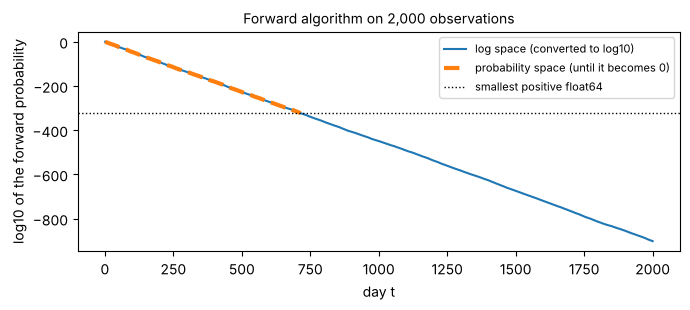

In [4]:
def logsumexp(x, axis=None):
    # log(sum(exp(x))) computed safely: subtract the maximum first
    m = np.max(x, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    with np.errstate(divide="ignore"):
        return np.squeeze(m, axis=axis) + np.log(np.sum(np.exp(x - m), axis=axis))

def forward_prob(pi, A, B, obs):
    # probability space: totals[t] = probability of the first t + 1 observations
    alpha = pi * B[:, obs[0]]; totals = [alpha.sum()]
    for o in obs[1:]:
        alpha = (alpha @ A) * B[:, o]; totals.append(alpha.sum())
    return np.array(totals)

def forward_log(pi, A, B, obs):
    # log space: the same recursion with + for * and log-sum-exp for +
    la = np.log(pi) + np.log(B[:, obs[0]]); totals = [logsumexp(la)]
    for o in obs[1:]:
        la = logsumexp(la[:, None] + np.log(A), axis=0) + np.log(B[:, o]); totals.append(logsumexp(la))
    return np.array(totals)

def forward_scaled(pi, A, B, obs):
    # probability space, but every column is rescaled to sum to 1 (Rabiner 1989)
    alpha = pi * B[:, obs[0]]; c = alpha.sum(); alpha = alpha / c; logp = np.log(c)
    for o in obs[1:]:
        alpha = (alpha @ A) * B[:, o]; c = alpha.sum(); alpha = alpha / c; logp += np.log(c)
    return logp

def viterbi_path(pi, A, B, obs, log_space=True):
    W0, WA, WB = (np.log(pi), np.log(A), np.log(B)) if log_space else (pi, A, B)
    comb = np.add if log_space else np.multiply
    d = comb(W0, WB[:, obs[0]]); back = []; top = [float(d.max())]
    for o in obs[1:]:
        cand = comb(d[:, None], WA)                      # cand[r, s]: best path into r, then the step r -> s
        back.append(cand.argmax(axis=0)); d = comb(cand.max(axis=0), WB[:, o]); top.append(float(d.max()))
    s = int(d.argmax()); path = [s]
    for bp in reversed(back):
        s = int(bp[s]); path.append(s)
    return path[::-1], top                               # the path, and the best score after every day

rng = np.random.default_rng(0)
T_long = 2000
hidden, obs_long = [], []
s = rng.choice(3, p=pi)
for t in range(T_long):                                  # sample the weather and what we observe (synthetic)
    hidden.append(int(s)); obs_long.append(int(rng.choice(3, p=B[s])))
    s = rng.choice(3, p=A[s])

assert viterbi_path(pi, A, B, obs10)[0] == viterbi_path(pi, A, B, obs10, log_space=False)[0] == path     # short: all agree
tot_p, tot_l = forward_prob(pi, A, B, obs_long), forward_log(pi, A, B, obs_long)
first_zero = int(np.argmax(tot_p == 0.0)) + 1
print(f"float64: smallest positive number {np.nextafter(0.0, 1.0):.1e}, smallest normal number {np.finfo(float).tiny:.1e}")
for day in [10, 100, 500, 700, 1000, 2000]:
    print(f"day {day:4d}: probability space {tot_p[day - 1]:10.3e} | log space: log p = {tot_l[day - 1]:10.3f}")
print(f"the probability-space forward value is exactly 0.0 from day {first_zero} on")
print(f"log p of all {T_long} observations: log space {tot_l[-1]:.4f}, rescaled columns {forward_scaled(pi, A, B, obs_long):.4f}; "
      f"that is {tot_l[-1] / T_long:.4f} per day, a probability of about 10^{tot_l[-1] / math.log(10):.0f}")

path_log, top_log = viterbi_path(pi, A, B, obs_long)
path_prob, top_prob = viterbi_path(pi, A, B, obs_long, log_space=False)
score_log = top_log[-1]
first_zero_v = top_prob.index(0.0) + 1
agree = sum(a == b for a, b in zip(path_log, path_prob))
first_diff = next(t for t in range(T_long) if path_log[t] != path_prob[t]) + 1
print(f"Viterbi, log space: best log-probability {score_log:.3f} ({score_log / T_long:.4f} per day); "
      f"probability space: best 'probability' {top_prob[-1]}")
print(f"the probability-space Viterbi score is exactly 0.0 from day {first_zero_v} on")
print(f"the two Viterbi paths agree on {agree} of {T_long} days; they first differ on day {first_diff}")
print(f"states in the probability-space path from day {first_diff} on: {sorted(set(path_prob[first_diff - 1:]))} (0 = sunny)")
print(f"days on which the path equals the true hidden weather: log space {sum(a == b for a, b in zip(path_log, hidden))}, "
      f"probability space {sum(a == b for a, b in zip(path_prob, hidden))} of {T_long}")

days = np.arange(1, T_long + 1)
with np.errstate(divide="ignore"):
    log10_p = np.log10(tot_p)
plt.figure(figsize=(7, 3.2))
plt.plot(days, tot_l / math.log(10), label="log space (converted to log10)")
plt.plot(days[tot_p > 0], log10_p[tot_p > 0], "--", lw=3, label="probability space (until it becomes 0)")
plt.axhline(math.log10(np.nextafter(0.0, 1.0)), color="k", ls=":", lw=1, label="smallest positive float64")
plt.xlabel("day t"); plt.ylabel("log10 of the forward probability")
plt.title("Forward algorithm on 2,000 observations", fontsize=10); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5. One function, several semirings
Sections 1 to 4 ran the same program each time: go through the edges of a lattice in topological order and update the value of each edge's end node. Only two operations changed:

* **times** combines the values along one path (multiply probabilities, or add log-probabilities);
* **plus** combines the paths that meet in a node (`max` for the best path, a sum for all paths).

A pair of operations with the right properties (both associative, **times** distributes over **plus**, and each has a neutral element, "zero" and "one") is called a **semiring**. Distributivity is the whole trick: $\max(a + c, b + c) = \max(a, b) + c$ and $(a + b) \cdot c = a \cdot c + b \cdot c$, so we may combine the paths into a node *before* we extend them. Goodman (1999) describes parsers this way: one program gives the best score, the total probability and other values when the semiring is swapped.

| semiring | plus | times | zero | one | value at the last node |
|---|---|---|---|---|---|
| Viterbi, on logs | max | + | −∞ | 0 | log-probability of the best path |
| log | log-sum-exp | + | −∞ | 0 | log of the total probability |
| probability | + | × | 0 | 1 | total probability (underflows for long inputs) |
| counting | + | × | 0 | 1 | number of paths, when every edge has weight 1 |

`lattice_dp` below is the whole algorithm: one pass over the edges. We give it the segmentation lattices of section 2 and the HMM lattices of sections 3 and 4 (a start node, $T$ layers of 3 nodes, an end node) and compare with the earlier results.

In [5]:
def logadd(a, b):
    # log(exp(a) + exp(b)) for two numbers
    if a == NEG: return b
    if b == NEG: return a
    m = max(a, b)
    return m + math.log(math.exp(a - m) + math.exp(b - m))

def lattice_dp(n_nodes, edges, plus, times, zero, one, weight=lambda lw: lw):
    # edges: (from, to, log-weight), sorted so that every edge INTO a node comes before any edge OUT of it.
    # Node 0 is the start and the last node is the end. Returns the value of the end node.
    value = [zero] * n_nodes
    value[0] = one
    for u, v, lw in edges:
        value[v] = plus(value[v], times(value[u], weight(lw)))
    return value[-1]

add, mul = (lambda a, b: a + b), (lambda a, b: a * b)
SEMIRINGS = [("best path: (max, +) on logs", max, add, NEG, 0.0, lambda lw: lw),
             ("all paths: (log-sum-exp, +) on logs", logadd, add, NEG, 0.0, lambda lw: lw),
             ("all paths: (+, x) on probabilities", add, mul, 0.0, 1.0, math.exp),
             ("number of paths: (+, x), weights 1", add, mul, 0, 1, lambda lw: 1)]

def segmentation_edges(text, logp, max_len):
    # one edge per vocabulary piece that matches the text, sorted by start position
    return [(j, i, logp[text[j:i]]) for j in range(len(text))
            for i in range(j + 1, min(len(text), j + max_len) + 1) if text[j:i] in logp]

def hmm_edges(pi, A, B, obs):
    # node 0 = start; node 1 + t * S + s = state s on day t; last node = end
    S, T = len(pi), len(obs)
    edges = [(0, 1 + s, math.log(pi[s] * B[s][obs[0]])) for s in range(S)]
    for t in range(1, T):
        edges += [(1 + (t - 1) * S + r, 1 + t * S + s, math.log(A[r][s] * B[s][obs[t]])) for r in range(S) for s in range(S)]
    edges += [(1 + (T - 1) * S + s, 1 + T * S, 0.0) for s in range(S)]
    return 2 + T * S, edges

lattices = [("nowhere, 6 pieces", len("nowhere") + 1, segmentation_edges("nowhere", logp1, 5)),
            (f"{bn_words[0]}, Bangla pieces", len(bn_words[0]) + 1, segmentation_edges(bn_words[0], bn_logp, bn_L)),
            ("HMM, 10 days", *hmm_edges(pi_l, A_l, B_l, obs10)),
            ("HMM, 2,000 days", *hmm_edges(pi_l, A_l, B_l, obs_long))]
results = {}
for name, n_nodes, edges in lattices:
    print(f"{name}: {n_nodes} nodes, {len(edges)} edges")
    for sname, plus, times, zero, one, weight in SEMIRINGS:
        r = lattice_dp(n_nodes, edges, plus, times, zero, one, weight)
        results[name, sname] = r
        shown = f"{r:.6g}" if isinstance(r, float) else (f"{r:,d}" if r < 10 ** 12 else f"a number with {len(str(r))} digits")
        print(f"   {sname:38s} {shown}")

# the same numbers as the special-purpose functions of sections 1 to 4
k_best, k_log, k_prob, k_count = [s[0] for s in SEMIRINGS]
checks = [abs(results["nowhere, 6 pieces", k_best] - best1[-1]) < 1e-12,
          abs(results["nowhere, 6 pieces", k_prob] - float(total1)) < 1e-12,
          results["nowhere, 6 pieces", k_count] == 3,
          abs(results["HMM, 10 days", k_best] - math.log(hmm_table(pi_l, A_l, B_l, obs10, "max")[0][1])) < 1e-9,
          abs(results["HMM, 10 days", k_prob] - hmm_table(pi_l, A_l, B_l, obs10, "sum")[0]) < 1e-15,
          results["HMM, 10 days", k_count] == 3 ** 10,
          abs(results["HMM, 2,000 days", k_best] - score_log) < 1e-6,
          abs(results["HMM, 2,000 days", k_log] - tot_l[-1]) < 1e-6,
          results["HMM, 2,000 days", k_count] == 3 ** 2000]
print("equal to the results of sections 1 to 4:", checks.count(True), "of", len(checks), "checks")

nowhere, 6 pieces: 8 nodes, 6 edges
   best path: (max, +) on logs            -2.77259
   all paths: (log-sum-exp, +) on logs    -2.54788
   all paths: (+, x) on probabilities     0.0782471
   number of paths: (+, x), weights 1     3
বাংলাদেশের, Bangla pieces: 11 nodes, 17 edges
   best path: (max, +) on logs            -3.21929
   all paths: (log-sum-exp, +) on logs    -3.05199
   all paths: (+, x) on probabilities     0.0472649
   number of paths: (+, x), weights 1     15
HMM, 10 days: 32 nodes, 87 edges
   best path: (max, +) on logs            -19.4062
   all paths: (log-sum-exp, +) on logs    -12.7217
   all paths: (+, x) on probabilities     2.98565e-06
   number of paths: (+, x), weights 1     59,049
HMM, 2,000 days: 6002 nodes, 17997 edges
   best path: (max, +) on logs            -3083.41
   all paths: (log-sum-exp, +) on logs    -2075.99
   all paths: (+, x) on probabilities     0
   number of paths: (+, x), weights 1     a number with 955 digits
equal to the results of secti

### 6. CTC: the forward table for a loss function
A speech recognizer outputs, for each of $T$ short frames of audio, a probability for every symbol. The training data give the text but not which frame belongs to which letter. **Connectionist temporal classification** (CTC; Graves et al. 2006) adds a **blank** symbol (written `-`) and reads a frame path by merging repeated symbols and then deleting blanks: `- m m - o o - o n -` gives `moon`. The probability of a text is the **sum over all frame paths (alignments) that collapse to it**, and the loss is minus its logarithm. Course 12 session 2 explains what this is for and trains a recognizer with `nn.CTCLoss`; here we build the table behind that loss.

**The lattice.** Put a blank before, between and after the $L$ letters of the target: `moon` becomes `- m - o - o - n -`, $2L + 1 = 9$ states. A path starts in one of the first two states and ends in one of the last two. From one frame to the next it may:

1. **stay** in the same state (a repeated symbol, or one more blank);
2. **step** to the next state;
3. **skip** the blank between two letters, but only if the two letters are **different**. Between the two `o`s of `moon` the blank cannot be skipped: without it `o o` would merge into one `o`.

**The table.** `alpha[t][s]` = the total probability of all partial paths that are in state $s$ at frame $t$:

`alpha[t][s] = (alpha[t-1][s] + alpha[t-1][s-1] + alpha[t-1][s-2] if the skip is allowed) * p[t][symbol of s]`

and the answer is the sum of the last two cells of the last row. The table has $T \cdot (2L + 1)$ cells with at most three terms each: $O(T \cdot L)$ time. We work in log space.

**By hand:** target `ab`, three frames, and count paths instead of adding probabilities (every weight 1). The states are `- a - b -`. Row 1 is `1 1 0 0 0`. Fill rows 2 and 3 and add the last two cells of row 3. Course 12 session 2 finds the same number by listing the paths.

The cell checks `ctc_forward` against brute force over all $C^T$ frame paths, for every text that can come out, and then compares the number of alignments with the number of table cells.

target ab, states - a - b -, number of partial paths:
   frame 1: [1, 1, 0, 0, 0]
   frame 2: [1, 2, 1, 1, 0]
   frame 3: [1, 3, 3, 4, 1]
alignments: 4 + 1 = 5; with probability 1/3 for every symbol the loss is -ln(5/27) = 1.6864 (Course 12 session 2 has the same 5 and 1.6864)

 T | frame paths 3^T | different texts | largest |forward - brute force| | sum over all texts
 1 |               3 |               3 |                        0.0e+00 | 1.000000000000
 2 |               9 |               5 |                        0.0e+00 | 1.000000000000
 3 |              27 |               9 |                        5.6e-17 | 1.000000000000
 4 |              81 |              15 |                        2.8e-17 | 1.000000000000
 5 |             243 |              25 |                        4.2e-17 | 1.000000000000
 6 |             729 |              41 |                        1.4e-16 | 1.000000000000
 7 |           2,187 |              67 |                        8.3e-17 | 1.000000000000
a te

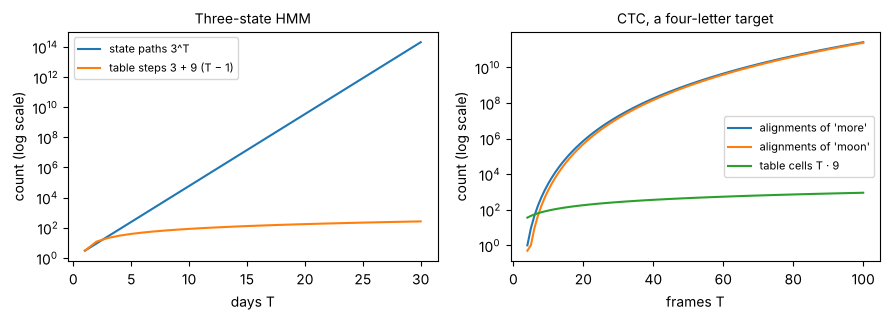

In [6]:
def collapse(path, blank=0):
    # merge repeated symbols, then delete blanks
    out, prev = [], None
    for c in path:
        if c != prev and c != blank:
            out.append(c)
        prev = c
    return tuple(out)

def extend(target, blank=0):
    ext = [blank]
    for c in target:
        ext += [c, blank]
    return ext                                           # blank, l1, blank, l2, ..., blank: 2 L + 1 states

def lse(xs):
    # log-sum-exp of a short list of numbers
    m = max(xs)
    return NEG if m == NEG else m + math.log(sum(math.exp(x - m) for x in xs))

def ctc_forward(logp, target, blank=0):
    # logp[t, c] = log-probability of symbol c at frame t. Returns (loss, table), loss = -log p(target).
    T, ext = len(logp), extend(target, blank)
    S = len(ext)
    alpha = np.full((T, S), NEG)
    alpha[0, 0] = logp[0, blank]                         # start with a blank ...
    if S > 1:
        alpha[0, 1] = logp[0, ext[1]]                    # ... or with the first letter
    for t in range(1, T):
        for s in range(S):
            cands = [alpha[t - 1, s]]                                        # stay
            if s >= 1:
                cands.append(alpha[t - 1, s - 1])                            # step
            if s >= 2 and ext[s] != blank and ext[s] != ext[s - 2]:
                cands.append(alpha[t - 1, s - 2])                            # skip a blank between two different letters
            alpha[t, s] = lse(cands) + logp[t, ext[s]]
    return -lse(list(alpha[T - 1, max(S - 2, 0):])), alpha                   # end in the last blank or the last letter

def ctc_count(T, target, blank=0):
    # the same table in the counting semiring: the number of frame paths that collapse to the target
    ext = extend(target, blank)
    S = len(ext)
    n = [[0] * S for _ in range(T)]
    n[0][0] = 1
    if S > 1:
        n[0][1] = 1
    for t in range(1, T):
        for s in range(S):
            n[t][s] = (n[t - 1][s] + (n[t - 1][s - 1] if s >= 1 else 0)
                       + (n[t - 1][s - 2] if s >= 2 and ext[s] != blank and ext[s] != ext[s - 2] else 0))
    return sum(n[T - 1][max(S - 2, 0):]), n

def ctc_brute(logp, blank=0):
    # every one of the C^T frame paths; returns {text: total probability}
    T, C = logp.shape
    table = {}
    for path in itertools.product(range(C), repeat=T):
        p = math.exp(sum(logp[t, c] for t, c in enumerate(path)))
        text = collapse(path, blank)
        table[text] = table.get(text, 0.0) + p
    return table

def log_softmax_np(z):
    return z - logsumexp(z, axis=-1)[..., None]

# by hand: target ab, 3 frames, counting
count_ab, n_ab = ctc_count(3, [1, 2])
print("target ab, states - a - b -, number of partial paths:")
for t, row in enumerate(n_ab):
    print(f"   frame {t + 1}: {row}")
uniform = np.full((3, 3), math.log(1 / 3))
print(f"alignments: {n_ab[-1][-2]} + {n_ab[-1][-1]} = {count_ab}; with probability 1/3 for every symbol the loss is "
      f"-ln({count_ab}/27) = {ctc_forward(uniform, [1, 2])[0]:.4f} (Course 12 session 2 has the same 5 and 1.6864)")

# against brute force: every text that can come out of T frames over the symbols -, a, b
rng = np.random.default_rng(8)
print("\n T | frame paths 3^T | different texts | largest |forward - brute force| | sum over all texts")
for T in [1, 2, 3, 4, 5, 6, 7]:
    logp = log_softmax_np(rng.normal(size=(T, 3)))
    table = ctc_brute(logp)
    worst = max(abs(math.exp(-ctc_forward(logp, list(text))[0]) - p) for text, p in table.items())
    print(f"{T:2d} | {3 ** T:15,d} | {len(table):15d} | {worst:30.1e} | {sum(table.values()):.12f}")
impossible = ctc_forward(logp, [1, 1, 1, 1, 1])[0]
print(f"a text that does not fit: aaaaa needs 5 letters + 4 blanks = 9 frames; with T = 7 the loss is {impossible}")

# number of alignments against table cells
LETTERS = "-emnor"                                        # symbol 0 is the blank
def ids(word):
    return [LETTERS.index(ch) for ch in word]
for word in ["more", "moon"]:
    for T in [4, 5, 6]:                                   # the count itself, checked by brute force over 5 symbols
        brute = sum(collapse(p) == tuple(ids(word)) for p in itertools.product([0] + sorted(set(ids(word))), repeat=T))
        assert brute == ctc_count(T, ids(word))[0]
print(f"\n{'frames T':>8s} | {'table cells T * 9':>17s} | {'alignments of more':>30s} | {'alignments of moon':>30s}")
for T in [4, 5, 6, 8, 10, 20, 50, 100]:
    c_more, c_moon = ctc_count(T, ids("more"))[0], ctc_count(T, ids("moon"))[0]
    assert c_more == math.comb(T + 4, 8)                  # no repeated neighbours: a binomial coefficient
    print(f"{T:8d} | {T * 9:17d} | {c_more:30,d} | {c_moon:30,d}")
print("for more (no double letter) the count equals the binomial coefficient C(T + 4, 8) in every row; brute force agrees for T = 4, 5, 6")

# an example to look at, written by hand (synthetic): 14 frames that say "moon"
frames = "-mm-oo-o--nn--"
P_moon = np.full((len(frames), len(LETTERS)), 0.06)
P_moon[np.arange(len(frames)), ids(frames)] = 0.70        # the intended symbol gets 0.70, the five others 0.06 each
P_moon[6] = 0.05                                          # frame 7, the blank between the two o's, is uncertain:
P_moon[6, LETTERS.index("-")], P_moon[6, LETTERS.index("o")] = 0.45, 0.35      # blank 0.45, o 0.35, the four others 0.05 each
assert np.allclose(P_moon.sum(axis=1), 1.0)
logp_moon = np.log(P_moon)
print(f"\n14 frames written by hand, most probable symbols: {''.join(LETTERS[c] for c in logp_moon.argmax(axis=1))}")
for word in ["moon", "mon", "more", "noon"]:
    loss, alpha_w = ctc_forward(logp_moon, ids(word))
    print(f"   loss for {word:5s}: {loss:7.3f}  (probability {math.exp(-loss):.6f}, {ctc_count(14, ids(word))[0]:,d} alignments, {alpha_w.size} cells)")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
Ts = np.arange(1, 31)
ax[0].semilogy(Ts, [3.0 ** T for T in Ts], label="state paths 3^T")
ax[0].semilogy(Ts, 3 + 9 * (Ts - 1), label="table steps 3 + 9 (T − 1)")
ax[0].set_xlabel("days T"); ax[0].set_ylabel("count (log scale)"); ax[0].set_title("Three-state HMM", fontsize=10); ax[0].legend(fontsize=8)
Ts = np.arange(4, 101)
ax[1].semilogy(Ts, [ctc_count(int(T), ids("more"))[0] for T in Ts], label="alignments of 'more'")
ax[1].semilogy(Ts, [max(ctc_count(int(T), ids("moon"))[0], 0.5) for T in Ts], label="alignments of 'moon'")
ax[1].semilogy(Ts, Ts * 9, label="table cells T · 9")
ax[1].set_xlabel("frames T"); ax[1].set_ylabel("count (log scale)"); ax[1].set_title("CTC, a four-letter target", fontsize=10); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 7. Check against PyTorch: the loss and its gradient
`torch.nn.functional.ctc_loss` is the tested implementation that Course 12 trains with. Our NumPy table must give the same number. We compare on random inputs of several shapes: different letters, double letters, three equal letters, long targets, an empty target, a text that is too long for the frames, and a padded batch. All inputs are float64, and `reduction="none"` asks PyTorch for one loss per sequence, as we compute it.

**The gradient.** Training needs the derivative of the loss with respect to the network's outputs. The loss is the last cell of a table in which every cell is a simple function of earlier cells: a computation graph (session 4). So we do not need a new formula: we write the same recursion with torch operations, and reverse-mode differentiation goes backwards through the table. That backward sweep through the lattice is what textbooks call the **backward algorithm** (Eisner 2016 shows this for the forward–backward algorithm in general). We compare the gradient with the one PyTorch computes for its own loss, with respect to the **logits** (the numbers before the log-softmax).

One detail: in the torch version an unreachable cell holds −10³⁰ in place of −∞. With a true −∞ the backward pass would compute 0 × NaN for cells that no path reaches.

PyTorch version: 2.15.0+cu132
case                       |   T |  C |  L | doubles | our NumPy loss |      PyTorch | difference
two different letters      |   5 |  3 |  2 |       0 |     1.32390508 |   1.32390508 | 2.2e-16
a double letter            |   6 |  3 |  2 |       1 |     6.33033594 |   6.33033594 | 0.0e+00
a double letter inside     |   8 |  4 |  4 |       1 |     9.23117593 |   9.23117593 | 0.0e+00
three equal letters        |  12 |  5 |  3 |       2 |    15.33347475 |  15.33347475 | 0.0e+00
random target              |  30 |  6 |  8 |       3 |    36.21851831 |  36.21851831 | 0.0e+00
random target              |  50 | 28 | 12 |       2 |   136.14382844 | 136.14382844 | 0.0e+00
random, 6 forced doubles   | 100 | 30 | 25 |       6 |   284.82514074 | 284.82514074 | 0.0e+00
long                       | 400 | 40 | 60 |      12 |  1300.92924181 | 1300.92924181 | 0.0e+00
empty target               |   4 |  5 |  0 |       0 |     7.38772147 |   7.38772147 | 0.0e+00
too few frames  

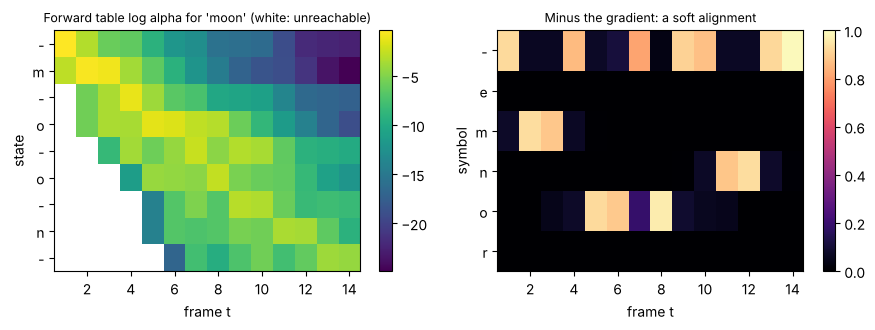

In [7]:
print("PyTorch version:", torch.__version__)

def torch_ctc(logp, target, reduction="none"):
    # PyTorch's loss for one sequence. logp: (T, C) NumPy array or tensor of log-probabilities.
    lp = torch.as_tensor(logp)[:, None, :]                                   # (T, batch of 1, C)
    return F.ctc_loss(lp, torch.tensor([target], dtype=torch.long), torch.tensor([lp.shape[0]]),
                      torch.tensor([len(target)]), blank=0, reduction=reduction)

rng = np.random.default_rng(9)
def random_target(L, C, doubles=0):
    t = rng.integers(1, C, size=L)
    for k in rng.choice(np.arange(1, L), size=doubles, replace=False):
        t[k] = t[k - 1]                                                      # force some double letters
    return t.tolist()

cases = [("two different letters", 5, 3, [1, 2]), ("a double letter", 6, 3, [1, 1]),
         ("a double letter inside", 8, 4, [1, 2, 2, 3]), ("three equal letters", 12, 5, [3, 3, 3]),
         ("random target", 30, 6, random_target(8, 6)), ("random target", 50, 28, random_target(12, 28)),
         ("random, 6 forced doubles", 100, 30, random_target(25, 30, doubles=6)),
         ("long", 400, 40, random_target(60, 40, doubles=10)),
         ("empty target", 4, 5, []), ("too few frames", 2, 3, [1, 1])]
print(f"{'case':26s} | {'T':>3s} | {'C':>2s} | {'L':>2s} | doubles | {'our NumPy loss':>14s} | {'PyTorch':>12s} | difference")
worst = 0.0
for name, T, C, target in cases:
    logp = log_softmax_np(rng.normal(size=(T, C)))
    ours, theirs = ctc_forward(logp, target)[0], float(torch_ctc(logp, target)[0])
    doubles = sum(a == b for a, b in zip(target, target[1:]))
    diff = "both inf" if ours == theirs == float("inf") else f"{abs(ours - theirs):.1e}"
    if diff != "both inf":
        worst = max(worst, abs(ours - theirs))
    print(f"{name:26s} | {T:3d} | {C:2d} | {len(target):2d} | {doubles:7d} | {ours:14.8f} | {theirs:12.8f} | {diff}")
print(f"largest difference over the finite cases: {worst:.1e}")

# a padded batch: three sequences with different numbers of frames and letters
Tmax, in_len, tgts = 20, [20, 14, 9], [[1, 2, 2, 3, 5], [4, 4], [2, 1, 2]]
logp_b = log_softmax_np(rng.normal(size=(Tmax, 3, 6)))                       # (T, batch, C), as PyTorch wants it
padded = np.zeros((3, 5), dtype=np.int64)
for i, t in enumerate(tgts):
    padded[i, :len(t)] = t
pt = F.ctc_loss(torch.tensor(logp_b), torch.tensor(padded), torch.tensor(in_len), torch.tensor([len(t) for t in tgts]),
                blank=0, reduction="none")
ours_b = [ctc_forward(logp_b[:in_len[i], i], tgts[i])[0] for i in range(3)]
print("\npadded batch, ours   :", ", ".join(f"{v:.8f}" for v in ours_b))
print("padded batch, PyTorch:", ", ".join(f"{float(v):.8f}" for v in pt))
default = float(F.ctc_loss(torch.tensor(logp_b), torch.tensor(padded), torch.tensor(in_len), torch.tensor([len(t) for t in tgts])))
print(f"PyTorch's default reduction ('mean') returns {default:.8f} = the mean of loss / target length = "
      f"{np.mean([v / len(t) for v, t in zip(ours_b, tgts)]):.8f}; the sum of our three losses is {sum(ours_b):.8f}")

def ctc_loss_torch_ops(logp, target, blank=0):
    # the recursion of ctc_forward with torch operations, one whole row of the table per step
    T, ext = logp.shape[0], torch.tensor(extend(target, blank))
    S, BIG = len(ext), -1e30                                                 # BIG stands for log 0
    can_skip = torch.zeros(S, dtype=torch.bool)
    can_skip[2:] = (ext[2:] != blank) & (ext[2:] != ext[:-2])
    emit = logp[:, ext]                                                      # emit[t, s] = logp[t, symbol of state s]
    neg = torch.full((S,), BIG, dtype=logp.dtype)
    alpha = torch.cat([emit[0, :2], neg[2:]])
    for t in range(1, T):
        step = torch.cat([neg[:1], alpha[:-1]])
        skip = torch.where(can_skip, torch.cat([neg[:2], alpha[:-2]])[:S], neg)
        alpha = torch.logsumexp(torch.stack([alpha, step, skip]), dim=0) + emit[t]
    return -torch.logsumexp(alpha[-2:], dim=0)

print(f"\n{'case':26s} | loss, torch recursion | loss, PyTorch | largest |gradient difference| w.r.t. the logits")
worst_g = 0.0
for name, T, C, target in cases[:8]:
    logits = torch.tensor(rng.normal(size=(T, C)), requires_grad=True)
    loss_a = ctc_loss_torch_ops(F.log_softmax(logits, dim=-1), target)
    g_a, = torch.autograd.grad(loss_a, logits)
    loss_b = torch_ctc(F.log_softmax(logits, dim=-1), target, reduction="sum")
    g_b, = torch.autograd.grad(loss_b, logits)
    worst_g = max(worst_g, float((g_a - g_b).abs().max()))
    print(f"{name:26s} | {loss_a.item():21.8f} | {loss_b.item():13.8f} | {float((g_a - g_b).abs().max()):.1e}")
print(f"largest gradient difference over the 8 cases: {worst_g:.1e}")

# the gradient with respect to the log-probabilities themselves (a leaf, no log-softmax in the graph), for the 'moon' example
moon = ids("moon")
lp_leaf = torch.tensor(logp_moon, requires_grad=True)
g_ours, = torch.autograd.grad(ctc_loss_torch_ops(lp_leaf, moon), lp_leaf)
g_pt, = torch.autograd.grad(torch_ctc(lp_leaf, moon, reduction="sum"), lp_leaf)
print(f"\nmoon, gradient w.r.t. the log-probabilities as a leaf: largest |ours - PyTorch| = {float((g_ours - g_pt).abs().max()):.4f}")
print(f"   largest |PyTorch - (ours + probabilities)| = {float((g_pt - g_ours - lp_leaf.detach().exp()).abs().max()):.1e}")
print(f"   row sums: ours {g_ours.sum(dim=1).min().item():.6f} to {g_ours.sum(dim=1).max().item():.6f}, "
      f"PyTorch {abs(g_pt.sum(dim=1)).max().item():.1e} at most in absolute value")
z = torch.tensor(logp_moon, requires_grad=True)             # the same numbers used as logits: log_softmax leaves them unchanged
g_logits, = torch.autograd.grad(ctc_loss_torch_ops(F.log_softmax(z, dim=-1), moon), z)
print(f"   largest |PyTorch's leaf gradient - our gradient w.r.t. the logits| = {float((g_pt - g_logits).abs().max()):.1e}")
occupancy = (-g_ours).numpy()                              # occupancy[t, c]: how much of the probability mass uses symbol c at frame t
print("   most probable symbol per frame under all alignments of moon:", "".join(LETTERS[c] for c in occupancy.argmax(axis=1)))

loss_moon, alpha_moon = ctc_forward(logp_moon, moon)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
im = ax[0].imshow(np.where(np.isfinite(alpha_moon), alpha_moon, np.nan).T, aspect="auto", cmap="viridis")
for a in ax:
    a.set_xticks(range(1, 14, 2)); a.set_xticklabels(range(2, 15, 2)); a.set_xlabel("frame t")
ax[0].set_yticks(range(9)); ax[0].set_yticklabels(list("-m-o-o-n-")); ax[0].set_ylabel("state")
ax[0].set_title("Forward table log alpha for 'moon' (white: unreachable)", fontsize=9); plt.colorbar(im, ax=ax[0])
im = ax[1].imshow(occupancy.T, aspect="auto", cmap="magma", vmin=0, vmax=1)
ax[1].set_yticks(range(len(LETTERS))); ax[1].set_yticklabels(list(LETTERS)); ax[1].set_ylabel("symbol")
ax[1].set_title("Minus the gradient: a soft alignment", fontsize=9); plt.colorbar(im, ax=ax[1])
plt.tight_layout(); plt.show()

### 8. The best path is not the most probable text
**Best-path (greedy) decoding** takes the most probable symbol of every frame and collapses the result. That is the single most probable *frame path*. But the probability of a *text* is a sum over all its alignments, and a text with many alignments can beat the text of the best path.

By hand: two frames, and in both the blank has probability 0.6 and `a` has 0.4. The best path is `- -` with probability 0.36, which collapses to the empty text. The text `a` has three alignments, `a -`, `- a` and `a a`: 0.24 + 0.24 + 0.16 = 0.64.

The cell does the same for three frames and three symbols by brute force. Then it asks how often this happens on random probability tables with 6 frames (synthetic; a random table is not a trained model). The tables are drawn from a Dirichlet distribution: a concentration of 1 gives uncertain frames, 0.1 gives frames where one symbol has nearly all the probability. For each table we find the most probable text exactly, from all $3^6 = 729$ paths.

Finding the most probable text exactly is hard: Graves et al. (2006) write that they know of no general, tractable algorithm for it, and they use approximations. Prefix beam search is a common one; Course 12 session 6 implements it.

In [8]:
P = np.array([[0.50, 0.40, 0.10],                         # columns: blank, a, b
              [0.60, 0.30, 0.10],
              [0.40, 0.35, 0.25]])
show = lambda text: "".join("-ab"[c] for c in text) or "(empty)"
table = ctc_brute(np.log(P))
greedy_path = P.argmax(axis=1)
print("best path:", "".join("-ab"[c] for c in greedy_path), f"with probability {P.max(axis=1).prod():.3f} -> text {show(collapse(greedy_path))}")
print("the most probable texts, summed over all 27 paths:")
for text, p in sorted(table.items(), key=lambda kv: (-kv[1], kv[0]))[:4]:
    n_align = ctc_count(3, list(text))[0]
    fwd = math.exp(-ctc_forward(np.log(P), list(text))[0])
    print(f"   {show(text):8s} probability {p:.4f} | alignments: {n_align} | forward table: {fwd:.4f}")

T6, C3 = 6, 3
paths = np.array(list(itertools.product(range(C3), repeat=T6)))               # 729 x 6
texts = [collapse(p) for p in paths]
uniq = sorted(set(texts))
text_id = np.array([uniq.index(t) for t in texts])
rng = np.random.default_rng(10)
print(f"\n{len(paths)} paths of {T6} frames collapse to {len(uniq)} different texts")
print("concentration | tables | greedy text is not the most probable text | mean P(greedy text) | mean P(most probable text)")
for conc in [1.0, 0.3, 0.1]:
    differ, p_greedy, p_best = 0, 0.0, 0.0
    for trial in range(2000):
        Pm = rng.dirichlet(np.full(C3, conc), size=T6)
        totals = np.bincount(text_id, weights=Pm[np.arange(T6), paths].prod(axis=1), minlength=len(uniq))
        g = uniq.index(collapse(Pm.argmax(axis=1)))
        differ += int(totals.argmax()) != g
        p_greedy += totals[g]; p_best += totals.max()
    print(f"{conc:13.1f} | {2000:6d} | {differ:41d} | {p_greedy / 2000:19.4f} | {p_best / 2000:26.4f}")
print(f"runtime so far {time.time() - t_start:.0f} s")

best path: --- with probability 0.120 -> text (empty)
the most probable texts, summed over all 27 paths:
   a        probability 0.4035 | alignments: 6 | forward table: 0.4035
   ab       probability 0.1535 | alignments: 5 | forward table: 0.1535
   b        probability 0.1380 | alignments: 6 | forward table: 0.1380
   (empty)  probability 0.1200 | alignments: 1 | forward table: 0.1200

729 paths of 6 frames collapse to 41 different texts
concentration | tables | greedy text is not the most probable text | mean P(greedy text) | mean P(most probable text)
          1.0 |   2000 |                                      1013 |              0.1944 |                     0.2348
          0.3 |   2000 |                                       437 |              0.3801 |                     0.3994


          0.1 |   2000 |                                       135 |              0.6428 |                     0.6489
runtime so far 2 s


### 9. The real tool: a unigram tokenizer in SentencePiece (NOT RUN)
SentencePiece (Kudo & Richardson 2018) trains a unigram model on a text file and then encodes with the algorithms of this notebook: the best segmentation, a sampled segmentation, or the $n$ best. The cell is written from the Python README of the library (read in November 2026). It needs the `sentencepiece` package and a text file of your own, so it is not run here. Course 5 session 4 trains tokenizers for Bangla.

In [ ]:
# NOT RUN: needs the sentencepiece library and a corpus file (pip install sentencepiece; put your own text in corpus.txt)
import sentencepiece as spm

# model_type is one of the library's training options ("unigram" or "bpe", among others); check the options of your version
spm.SentencePieceTrainer.train(input="corpus.txt", model_prefix="uni", vocab_size=1000, model_type="unigram")
sp = spm.SentencePieceProcessor(model_file="uni.model")

text = "বাংলাদেশের মানুষ"
print(sp.encode(text, return_type=str))                     # the best segmentation (older versions: out_type=str)
for _ in range(3):                                         # sampled segmentations: a different one each call
    print(sp.encode(text, return_type=str, enable_sampling=True, alpha=0.1, nbest_size=-1))
print(sp.nbest_encode(text, nbest_size=3, return_type=str))  # the three best segmentations

### 10. Exercises

In [9]:
# TODO: forced alignment. Copy ctc_forward and change it to the Viterbi semiring: take the MAXIMUM of the candidates
# in place of their log-sum-exp, and store for every cell which candidate won (a back-pointer). Follow the back-pointers
# from the better of the last two cells and return the best frame path as a list of T symbols.
# Checks: collapse(path) == tuple(target); the path's log-probability is not larger than -ctc_forward(logp, target)[0];
# for logp_moon and "moon", compare the path with the frames string of section 6.
# Course 12 session 3 uses exactly this table to put times on caption words.
def ctc_best_alignment(logp, target, blank=0):
    return None          # replace with your code

r = ctc_best_alignment(logp_moon, ids("moon"))
print("not done yet" if r is None else "".join(LETTERS[c] for c in r))

not done yet


In [10]:
# TODO: sample a segmentation. With the (+, x) table, total[i] = the sum of the probabilities of all segmentations of text[:i].
# Walk backwards from i = n: choose the last piece text[j:i] with probability total[j] * p(text[j:i]) / total[i], then
# continue from j. Every segmentation is then drawn with a probability proportional to its product (Kudo 2018 trains
# translation models on segmentations sampled like this). Return the list of pieces.
# Check: in 10,000 samples of "nowhere" the three segmentations should appear in the proportions 512 : 128 : 1 (section 2).
def sample_segmentation(text, logp, max_len, rng):
    return None          # replace with your code

r = sample_segmentation("nowhere", logp1, 5, np.random.default_rng(0))
print("not done yet" if r is None else r)

not done yet


### What to notice
(Written from the run above. The counts are exact and will be the same on your machine; the timings will not.)

1. **One table, and a back-pointer.** For `nowhere` the table gives `no | where` with probability 1/16 after 25 vocabulary lookups. Brute force tried all 64 ways to cut and found the same answer among the 3 valid ones. Positions 4, 5 and 6 keep the cost ∞: no vocabulary piece ends there.
2. **Greedy longest match is a different algorithm with a different answer.** It takes `now` first and ends with `now | here`, which is 4 times less probable. On 300 random strings Viterbi matched brute force every time; greedy found the best score in 230 and a lower one in 70. For `বাংলাদেশের` greedy takes the longer piece `বাংলাদেশে` and is left with a single `র` (probability 0.000200), where Viterbi cuts `বাংলাদেশ | ের` (0.039983). For the other two words both give the whole word.
3. **Exponential against linear.** A 16-letter string has 32,768 ways to cut and the table needed 58 lookups; for 80 letters it is 604,462,909,807,314,587,353,088 against 314. For the HMM, 100 days have $3^{100}$ state paths (48 digits) and the table takes 894 steps.
4. **Change max to sum.** The same loop gave the best path (probability 0.00504 for the three-day example) and the total over all 27 paths (0.03273), and both agreed with brute force. One thing was not as simple as planned: in 5 of the 80 random sequences Viterbi and brute force returned *different* paths with the *same* probability. A best path is not always unique, so compare scores, not paths.
5. **Probabilities underflow, logarithms do not.** The forward value in probability space was exactly 0.0 from day 715 on. In log space the answer is −2075.9905 (a probability of about 10⁻⁹⁰²), and Rabiner's rescaling gives the same number. Viterbi fails earlier, on day 484, because the best single path shrinks faster (−1.5417 per day) than the sum over all paths (−1.0380 per day). And it fails silently: after day 484 the probability-space path says `sunny` every day, and it agrees with the correct path on only 1,329 of 2,000 days.
6. **The best path is still a guess.** The correct Viterbi path equals the sampled hidden weather on 1,038 of 2,000 days. Viterbi finds the most probable path under the model; it cannot recover what the observations do not show.
7. **Semirings.** One short function reproduced all nine earlier results; only its two operations changed. With "count" it says that the 2,000-day lattice has a number of paths with 955 digits, through 17,997 edges.
8. **CTC is the forward algorithm on a lattice with blanks.** By hand: 5 alignments of `ab` in 3 frames, loss 1.6864, as in Course 12 session 2. The table equalled the brute-force sum for every text that can come out of up to 7 frames (2,187 paths, 67 texts, largest difference 1.4e-16), and the probabilities of all texts added up to 1. `more` has 257,575,523,205 alignments in 100 frames, and the table has 900 cells. `moon` has fewer (237,762,021,420) because the blank between the two `o`s cannot be skipped, and none at all in 4 frames.
9. **Our loss is PyTorch's loss.** On nine inputs with a finite loss, from 4 to 400 frames, with double letters and with an empty target, the largest difference was 2.2e-16; with too few frames both returned `inf`. Note what PyTorch's default does: `reduction="mean"` returned 6.64545291, the mean of loss / target length, not the sum 57.19493183.
10. **The gradient needs no new formula, with one trap.** The same recursion in torch operations gave PyTorch's gradient with respect to the logits within 1.0e-12 on all eight cases. But with respect to the log-probabilities taken as a leaf, PyTorch 2.15 returned our gradient **plus the probabilities** (largest difference 0.7000). That is the gradient for logits behind a log-softmax: its rows sum to 0, ours to −1. Behind a log-softmax both lead to the same update, so training is not affected; it matters only if you change the log-probabilities in some other way before the loss.
11. **Minus our gradient is a soft alignment.** Each row of it sums to 1: it says how much of the target's probability passes through each symbol at each frame. The right-hand plot shows `m`, the two `o`s and `n` in their places, and frame 7 shared between the blank and `o`.
12. **Greedy decoding returns the best path, not the best text.** In the three-frame example the best path is all blanks (0.120), so greedy returns the empty text, but `a` has probability 0.4035 from its 6 alignments. On random tables with uncertain frames this happened in 1,013 of 2,000 cases; with confident frames (concentration 0.1) in 135 of 2,000. Random tables are not trained models: in Course 12 session 6 greedy decoding and prefix beam search differ little (gloss WER 0.015 and 0.013).
13. Everything here is small and synthetic, and the loops are pure Python. Real implementations run the same recursions over a whole batch at once.